# Листок № 2. Комплексные числа и их геометрия

Решены **все пункты 2.1–2.10**, включая задания со звёздочкой и два разных задания с номером 2.10. Источник: «Практические занятия Листок 2.pdf», П. Е. Рябов. Вычисления воспроизводятся сверху вниз; численные ответы помечены знаком ≈. Код снабжён пояснениями, а рисунки строятся непосредственно в ноутбуке.

**Замечание к условию:** в 2.4(e) записано $-2\pi/3\le\arg w\le-5\pi/6$, хотя $-2\pi/3>-5\pi/6$. Буквально это пустое множество. Возможное исправление с переставленными границами показано отдельно и не подменяет ответ.

In [1]:
# Если библиотеки не установлены, выполните эту строку один раз:
# %pip install numpy sympy scipy mpmath matplotlib
import cmath
import math
import numpy as np
import sympy as sp
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.special import loggamma
from IPython.display import display, Math
sp.init_printing()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
def out(label, expr):
    print(label)
    display(expr)
def polar(z):
    # z = r(cos φ+i sin φ) = r exp(iφ), φ — главное значение аргумента.
    a = complex(sp.N(z, 16))
    return abs(a), cmath.phase(a)

## 2.1. Три формы комплексного числа

Для $z=a+bi$ модуль $r=\sqrt{a^2+b^2}$ и главный аргумент $\varphi=\operatorname{atan2}(b,a)$. Тогда $z=r(\cos\varphi+i\sin\varphi)=re^{i\varphi}$.

В пункте (c) основания числителей сопряжены. Можно проверить результат прямым точным раскрытием степеней; переход в тригонометрическую и показательную формы делается общей формулой выше. Для нулевого результата аргумент не определён, поэтому код это явно учитывает.

In [2]:
I=sp.I
z21 = [sp.simplify((5+I)*(7-6*I)/(3+I)),
       sp.simplify((1+I)**5/(1-I)**3),
       sp.simplify((-1+I*sp.sqrt(3))**15/(1-I)**20 + (-1-I*sp.sqrt(3))**15/(1+I)**20)]
for label,z in zip('abc', z21):
    z=sp.simplify(sp.expand_complex(z))
    print(f'{label}) алгебраическая форма:',z)
    if z != 0:
        r,phi=polar(z)
        print(f'   тригонометрическая: {r:.12g}(cos({phi:.12g})+i sin({phi:.12g}))')
        print(f'   показательная: {r:.12g} exp(i·{phi:.12g})')
    else:
        print('   обе остальные формы: 0; аргумент не определён')

a) алгебраическая форма: 10 - 11*I
   тригонометрическая: 14.8660687473(cos(-0.832981266674)+i sin(-0.832981266674))
   показательная: 14.8660687473 exp(i·-0.832981266674)
b) алгебраическая форма: 2
   тригонометрическая: 2(cos(0)+i sin(0))
   показательная: 2 exp(i·0)
c) алгебраическая форма: -64
   тригонометрическая: 64(cos(3.14159265359)+i sin(3.14159265359))
   показательная: 64 exp(i·3.14159265359)


## 2.2. Корни уравнения $z^8=1+i$

$1+i=\sqrt2\,e^{i\pi/4}$. По формуле Муавра восемь корней равны
$$z_k=2^{1/16}\exp\left(i\left(\frac{\pi}{32}+\frac{k\pi}{4}\right)\right),\quad k=0,\ldots,7.$$
Все они лежат на окружности радиуса $2^{1/16}$ и образуют правильный восьмиугольник.

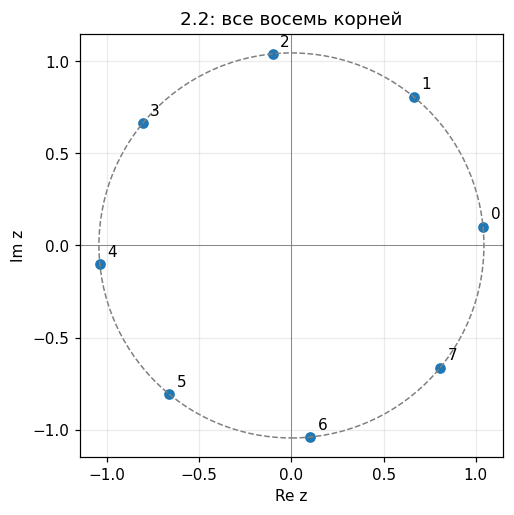

In [3]:
roots22=np.array([2**(1/16)*np.exp(1j*(np.pi/32+k*np.pi/4)) for k in range(8)])
assert np.allclose(roots22**8,1+1j)
fig,ax=plt.subplots(figsize=(5,5))
ax.scatter(roots22.real,roots22.imag)
for k,z in enumerate(roots22): ax.annotate(str(k),(z.real,z.imag),xytext=(5,5),textcoords='offset points')
ax.add_patch(plt.Circle((0,0),2**(1/16),fill=False,ls='--',color='gray'))
ax.axhline(0,color='gray',lw=.6); ax.axvline(0,color='gray',lw=.6)
ax.set(xlabel='Re z',ylabel='Im z',title='2.2: все восемь корней'); ax.set_aspect('equal'); ax.grid(alpha=.25)
plt.show()

## 2.3. Все значения корней

Если $w=Re^{i\theta}$, то все корни степени $n$ задаются $R^{1/n}e^{i(\theta+2\pi k)/n}$, $k=0,\ldots,n-1$. Для (a) $R=1,\theta=0$; для (d) $R=\sqrt2,\theta=-\pi/4$. В (b) и (c) сначала упрощаем подкоренное выражение. Рисунки показывают все корни, включая разные ветви.

a) подкоренное выражение = 1; корни: R^(1/8) exp(i(θ+2πk)/8), k=0,…,7; R=1, θ=0
b) подкоренное выражение = 18*I/(sqrt(3) - I); корни: R^(1/4) exp(i(θ+2πk)/4), k=0,…,3; R=9, θ=2.0943951
c) подкоренное выражение = 9 - 8*I; корни: R^(1/3) exp(i(θ+2πk)/3), k=0,…,2; R=12.0415946, θ=-0.726642341
d) подкоренное выражение = 1 - I; корни: R^(1/9) exp(i(θ+2πk)/9), k=0,…,8; R=1.41421356, θ=-0.785398163


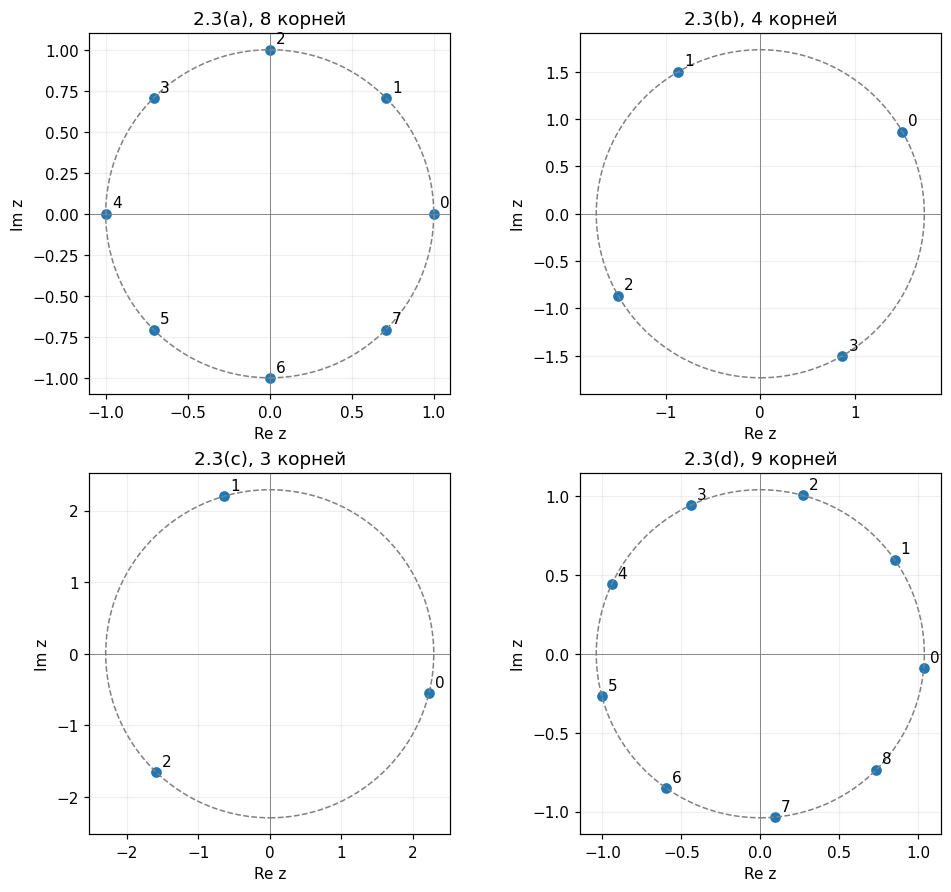

In [4]:
radicands23=[sp.Integer(1),sp.simplify(-18/(1+I*sp.sqrt(3))),
            sp.simplify((1-5*I)/(1+I)-5*(1+2*I)/(2-I)+11),1-I]
degrees23=[8,4,3,9]
fig,axes=plt.subplots(2,2,figsize=(9,8),layout='constrained')
for ax,label,w,n in zip(axes.flat,'abcd',radicands23,degrees23):
    R,theta=polar(w)
    roots=np.array([R**(1/n)*np.exp(1j*(theta+2*np.pi*k)/n) for k in range(n)])
    print(f'{label}) подкоренное выражение = {w}; корни: R^(1/{n}) exp(i(θ+2πk)/{n}), k=0,…,{n-1}; R={R:.9g}, θ={theta:.9g}')
    assert np.allclose(roots**n,complex(sp.N(w)))
    ax.scatter(roots.real,roots.imag)
    for k,z in enumerate(roots): ax.annotate(str(k),(z.real,z.imag),xytext=(4,4),textcoords='offset points')
    ax.add_patch(plt.Circle((0,0),R**(1/n),fill=False,ls='--',color='gray'))
    ax.axhline(0,color='gray',lw=.6);ax.axvline(0,color='gray',lw=.6)
    ax.set(title=f'2.3({label}), {n} корней',xlabel='Re z',ylabel='Im z');ax.set_aspect('equal');ax.grid(alpha=.2)
plt.show()

## 2.4. Геометрические места точек

Пусть $z=x+iy$.

- **(a)** Сумма расстояний до $i$ и $-i$ меньше 4: внутренность эллипса $x^2/3+y^2/4<1$; граница не входит.
- **(b)** $\Re(z(1-i))=x+y$, поэтому полуплоскость $x+y<\sqrt2$.
- **(c)** Из $|z+i|=|z-i|$ получаем $y=0$; затем $|z+1|=|z+i|$ даёт $x=0$. Ответ: только $z=0$.
- **(d)** $w=(i-z)/(z+i)$ должен лежать в открытом первом квадранте: $\Re w>0,\Im w>0$, при $z\ne-i$.
- **(e)** буквальное условие невозможно, так как левая граница больше правой. Если границы поменять местами, возникнет непустая область; её контур показан пунктиром.
- **(f)** $w=(3-z)/(z+i)$ должен иметь главный аргумент в замкнутом секторе $[-2\pi/3,-\pi/3]$, при $z\ne-i$.

Для (d), (f) численно закрашиваем точки, удовлетворяющие условиям. Чёрные точки исключены там, где знаменатель равен нулю.

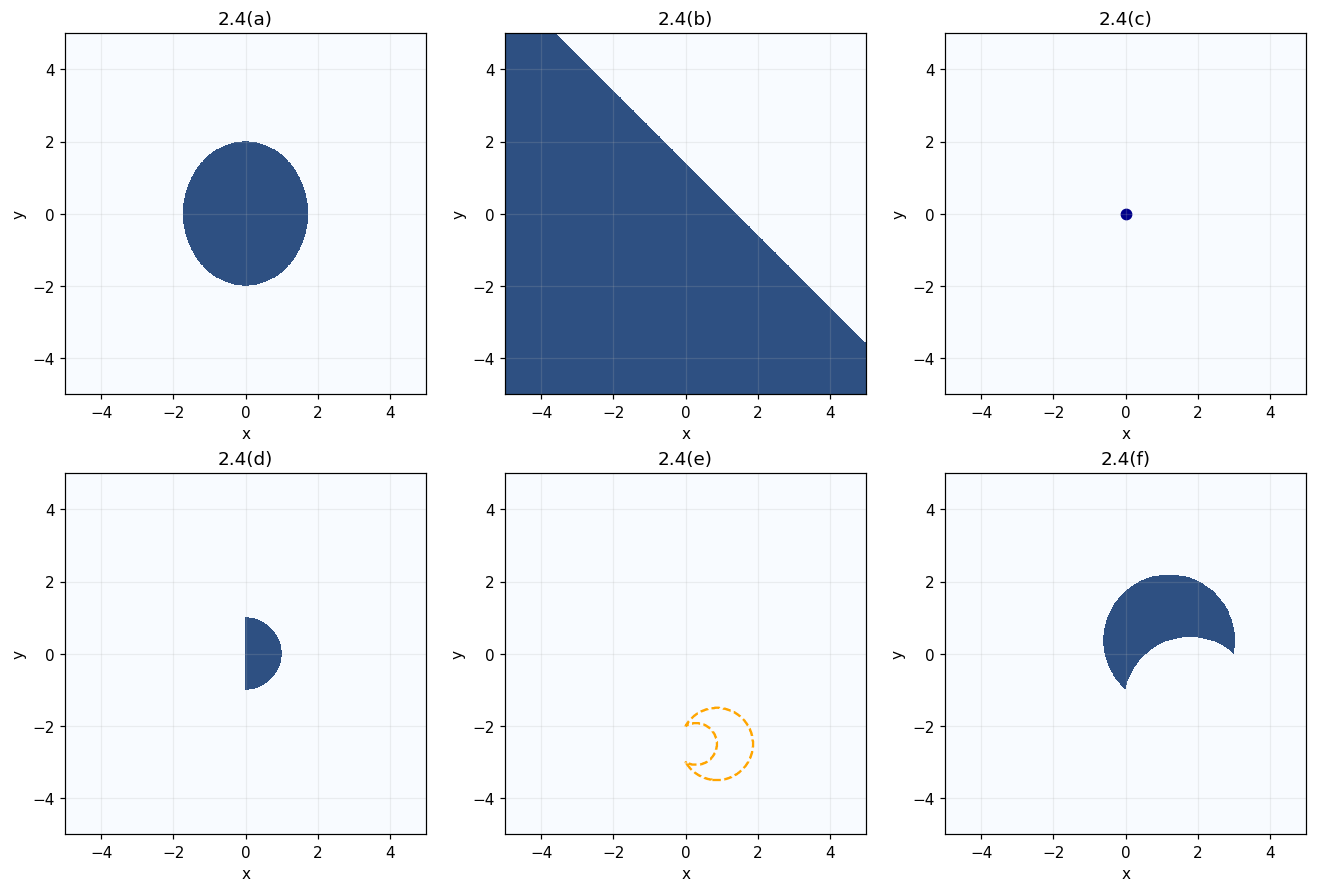

In [5]:
xx,yy=np.meshgrid(np.linspace(-5,5,750),np.linspace(-5,5,750)); zz=xx+1j*yy
with np.errstate(divide='ignore',invalid='ignore'):
    wd=(1j-zz)/(zz+1j)
    we=(2-1j*zz)/(zz+3j)
    wf=(3-zz)/(zz+1j)
masks24=[xx**2/3+yy**2/4<1, xx+yy<np.sqrt(2),np.zeros_like(xx,dtype=bool),
         (wd.real>0)&(wd.imag>0)&(np.abs(zz+1j)>1e-9),
         np.zeros_like(xx,dtype=bool),
         (np.angle(wf)>=-2*np.pi/3)&(np.angle(wf)<=-np.pi/3)&(np.abs(zz+1j)>1e-9)]
fig,axes=plt.subplots(2,3,figsize=(12,8),layout='constrained')
for ax,label,mask in zip(axes.flat,'abcdef',masks24):
    ax.imshow(mask,origin='lower',extent=(-5,5,-5,5),cmap='Blues',alpha=.85,interpolation='nearest')
    if label=='c': ax.scatter([0],[0],color='darkblue',s=45)
    if label=='e':
        repaired=(np.angle(we)>=-5*np.pi/6)&(np.angle(we)<=-2*np.pi/3)&(np.abs(zz+3j)>1e-9)
        ax.contour(xx,yy,repaired.astype(float),levels=[.5],colors=['orange'],linestyles='dashed')
    ax.set(title='2.4('+label+')',xlabel='x',ylabel='y',xlim=(-5,5),ylim=(-5,5));ax.set_aspect('equal');ax.grid(alpha=.2)
plt.show()

## 2.5. Окружность с комплексными коэффициентами

В условии $A,C\in\mathbb R$, $B\in\mathbb C$, $A>0$, $AC<|B|^2$. По тождеству
$$A|z|^2+\overline Bz+B\overline z+C=A\left|z+\frac BA\right|^2+C-\frac{|B|^2}{A}.$$
Значит, центр $z_0=-B/A$, радиус $r=\sqrt{|B|^2-AC}/A>0$. Неравенство гарантирует действительный ненулевой радиус.

In [6]:
A,B,C,z,zbar=sp.symbols('A B C z zbar')
lhs=A*z*zbar+sp.conjugate(B)*z+B*zbar+C
rhs=A*(z+B/A)*(zbar+sp.conjugate(B)/A)+C-B*sp.conjugate(B)/A
assert sp.simplify(lhs-rhs)==0
print('Центр = -B/A; радиус = sqrt(|B|²-AC)/A')

Центр = -B/A; радиус = sqrt(|B|²-AC)/A


## 2.6. Корни многочлена степени 11

Строим многочлен точно. `nroots` численно находит все комплексные корни; остатки $|p(z_k)|$ проверяют качество приближения. Сумма модулей не является стандартной формулой Виета, поэтому её считаем по найденным корням.

In [7]:
t=sp.symbols('t')
p26=t**11+t**10+t**8-2*t**7-t**5+t**4+2*t**2+2*t+2
roots26=sp.nroots(p26,n=30,maxsteps=200)
for k,r in enumerate(roots26,1): print(f'z{k} = {complex(r):.12g}')
sum26=sum(abs(complex(r)) for r in roots26)
maxre26=max(complex(r).real for r in roots26)
print('Сумма модулей ≈',format(sum26,'.12f'))
print('Максимальная действительная часть ≈',format(maxre26,'.12f'))
assert len(roots26)==11
assert max(abs(complex(sp.N(p26.subs(t,r),20))) for r in roots26)<1e-15

z1 = -1.77676902492+0j
z2 = -0.707434455212-0.464374725865j
z3 = -0.707434455212+0.464374725865j
z4 = -0.450037112743-0.803923144248j
z5 = -0.450037112743+0.803923144248j
z6 = -0.0125001805645-1.18269908175j
z7 = -0.0125001805645+1.18269908175j
z8 = 0.477754523623-0.901075230538j
z9 = 0.477754523623+0.901075230538j
z10 = 1.08060173736-0.32389311884j
z11 = 1.08060173736+0.32389311884j
Сумма модулей ≈ 11.973384469712
Максимальная действительная часть ≈ 1.080601737358


## 2.7. Обобщённые биномиальные коэффициенты

$C_z^w=\Gamma(z+1)/[\Gamma(w+1)\Gamma(z-w+1)]$. В (a),(b) берём $z=1+i$, $w=1-i$. В (c) строим линии уровня главного аргумента $C_z^{1/z}$ для $z=x+iy$. Через `loggamma` вычисляем логарифм отношения гамма-функций: это устойчивее прямого деления больших комплексных чисел. Полюса и точки вблизи $z=0$ маскируются.

C_(1+i)^(1-i) = (4.3674491406401389672 + 4.8516297651578115409j)
Arg = 0.837869369550042 рад = 48.0063786585 град


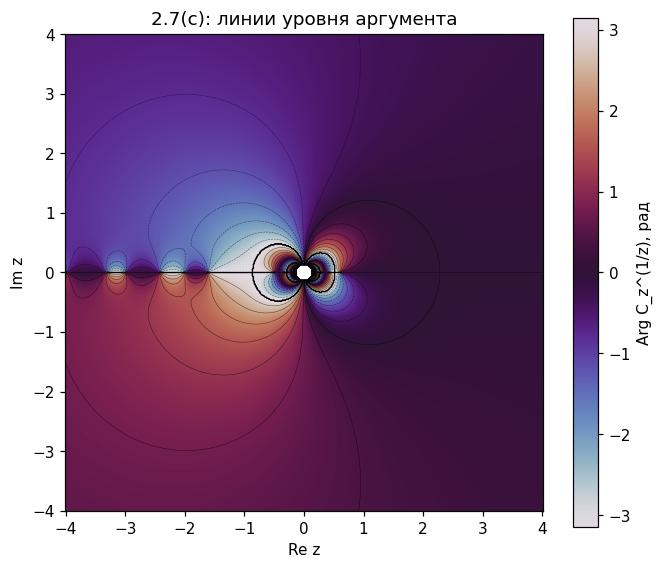

In [8]:
mp.mp.dps=35
coef27=mp.gamma(2+1j)/(mp.gamma(2-1j)*mp.gamma(1+2j))
print('C_(1+i)^(1-i) =',mp.nstr(coef27,20))
print('Arg =',mp.nstr(mp.arg(coef27),15),'рад =',mp.nstr(mp.degrees(mp.arg(coef27)),12),'град')
assert abs(complex(coef27)-complex(4.36745,4.85163))<2e-5
grid=np.linspace(-4,4,500)
X,Y=np.meshgrid(grid,grid); Z=X+1j*Y
with np.errstate(divide='ignore',invalid='ignore',over='ignore'):
    W=1/Z
    logC=loggamma(Z+1)-loggamma(W+1)-loggamma(Z-W+1)
    phase=np.angle(np.exp(1j*np.imag(logC)))
phase[~np.isfinite(phase)|(np.abs(Z)<.12)]=np.nan
fig,ax=plt.subplots(figsize=(7,6))
im=ax.pcolormesh(X,Y,phase,cmap='twilight',vmin=-np.pi,vmax=np.pi,shading='auto',rasterized=True)
ax.contour(X,Y,phase,levels=np.linspace(-np.pi,np.pi,17),colors='k',linewidths=.35,alpha=.6)
fig.colorbar(im,ax=ax,label='Arg C_z^(1/z), рад')
ax.set(title='2.7(c): линии уровня аргумента',xlabel='Re z',ylabel='Im z');ax.set_aspect('equal')
plt.show()

## 2.8. Определитель с корнем из единицы

Среди четырнадцатых корней единицы с положительной мнимой частью максимальную действительную часть имеет $\lambda=e^{i\pi/7}$. Для $A=\left(\begin{smallmatrix}7&5\\6&2\end{smallmatrix}\right)$
$$\det(A+\lambda I)=(7+\lambda)(2+\lambda)-30=\lambda^2+9\lambda-16.$$
Отсюда $\Re\det=\cos(2\pi/7)+9\cos(\pi/7)-16$, $\Im\det=\sin(2\pi/7)+9\sin(\pi/7)$.

In [9]:
lam28=np.exp(1j*np.pi/7)
A28=np.array([[7,5],[6,2]],dtype=complex)
det28=np.linalg.det(A28+lam28*np.eye(2))
assert np.isclose(det28,lam28**2+9*lam28-16)
print('Re det ≈',format(det28.real,'.12f'))
print('Im det ≈',format(det28.imag,'.12f'))

Re det ≈ -7.267790387019
Im det ≈ 4.686785134526


## 2.9. Множества Жюлиа

Для каждого пикселя берём начальную точку $z_0$ и повторяем $z_{n+1}=f(z_n)$. Цвет зависит от числа итераций до выхода за радиус. Для полинома $z^2+c$ радиус 10 достаточен: если $|z|>10$, орбита стремится к бесконечности. Для рациональных функций в (г) используется та же **визуализация времени выхода**, но это лишь численное изображение их динамики; из-за полюсов и сложной динамики его нельзя считать строгим определением множества Жюлиа. Контрастные границы уточняются увеличением разрешения и числа итераций.

В исходном примере PDF код содержит другую функцию на одной строке; здесь реализованы именно формулы задания. При делении на ноль используется маска.

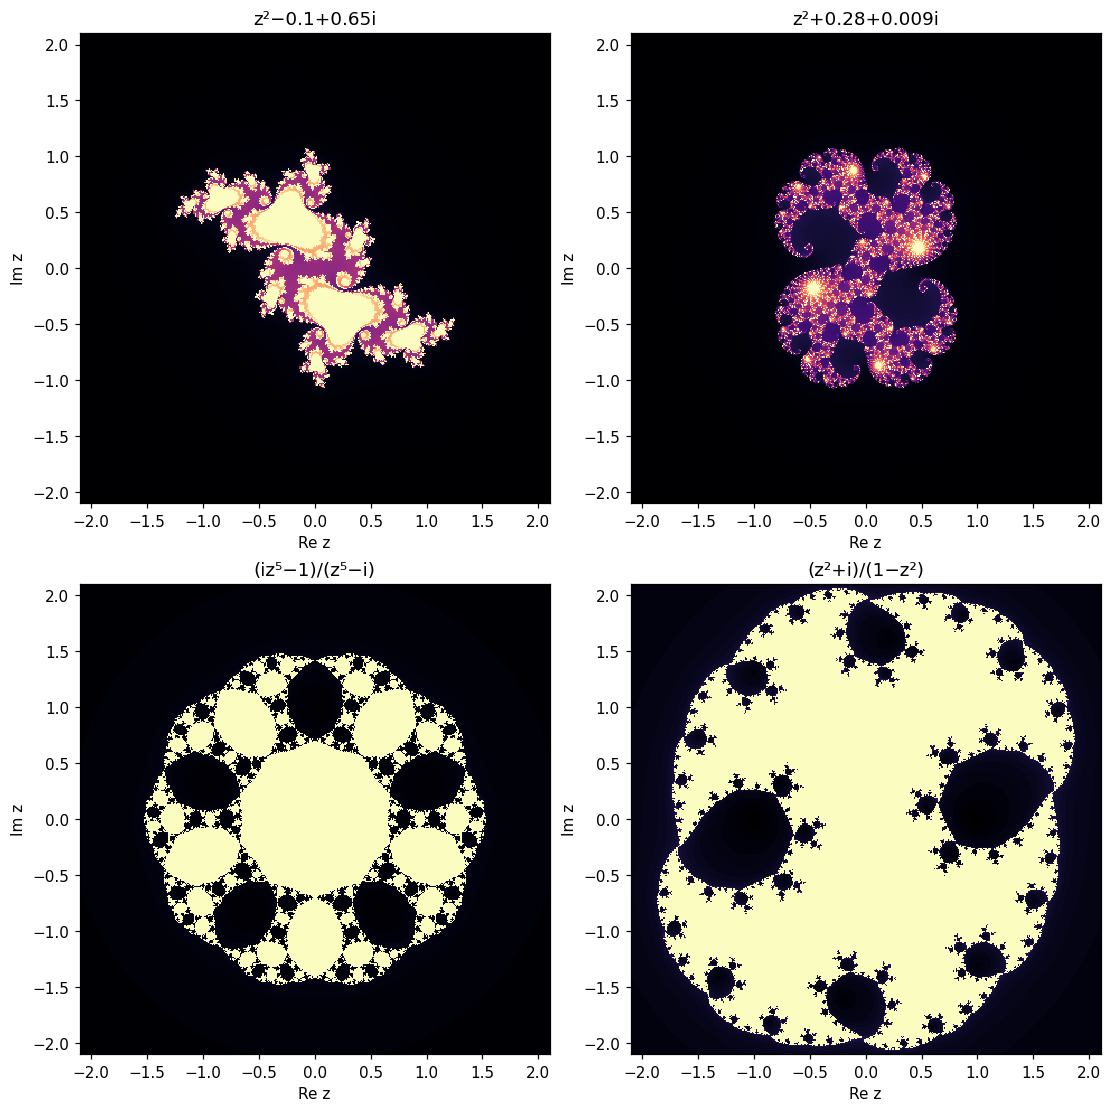

In [10]:
def escape_image(kind, size=420, steps=180):
    x=np.linspace(-2.1,2.1,size); y=np.linspace(-2.1,2.1,size)
    X,Y=np.meshgrid(x,y); Z=X+1j*Y
    escape=np.full(Z.shape,steps,dtype=np.int32); active=np.ones(Z.shape,dtype=bool)
    for it in range(steps):
        with np.errstate(all='ignore'):
            if kind=='a': Z=Z*Z+(-.1+.65j)
            elif kind=='b': Z=Z*Z+(.28+.009j)
            elif kind=='c': Z=(1j*Z**5-1)/(Z**5-1j)
            else: Z=(Z*Z+1j)/(1-Z*Z)
        escaped=active&((np.abs(Z)>10)|~np.isfinite(Z))
        escape[escaped]=it+1
        active&=~escaped
        if not active.any(): break
    return escape
fig,axes=plt.subplots(2,2,figsize=(10,10),layout='constrained')
for ax,kind,title in zip(axes.flat,'abcd',['z²−0.1+0.65i','z²+0.28+0.009i','(iz⁵−1)/(z⁵−i)','(z²+i)/(1−z²)']):
    image=escape_image(kind)
    ax.imshow(image,extent=(-2.1,2.1,-2.1,2.1),origin='lower',cmap='magma',interpolation='nearest')
    ax.set(title=title,xlabel='Re z',ylabel='Im z')
plt.show()

## 2.10 (первое). Кривые на сфере Римана

Используем обратную стереографическую проекцию комплексной плоскости на единичную сферу:
$$z=x+iy\longmapsto \left(\frac{2x}{1+x^2+y^2},\frac{2y}{1+x^2+y^2},\frac{x^2+y^2-1}{1+x^2+y^2}\right).$$
Бесконечно удалённая точка соответствует северному полюсу $(0,0,1)$. Прямая, окружность, парабола и ветви гиперболы параметризуются в плоскости, затем переводятся на сферу. Конечный диапазон параметра только приближает бесконечные части кривых.

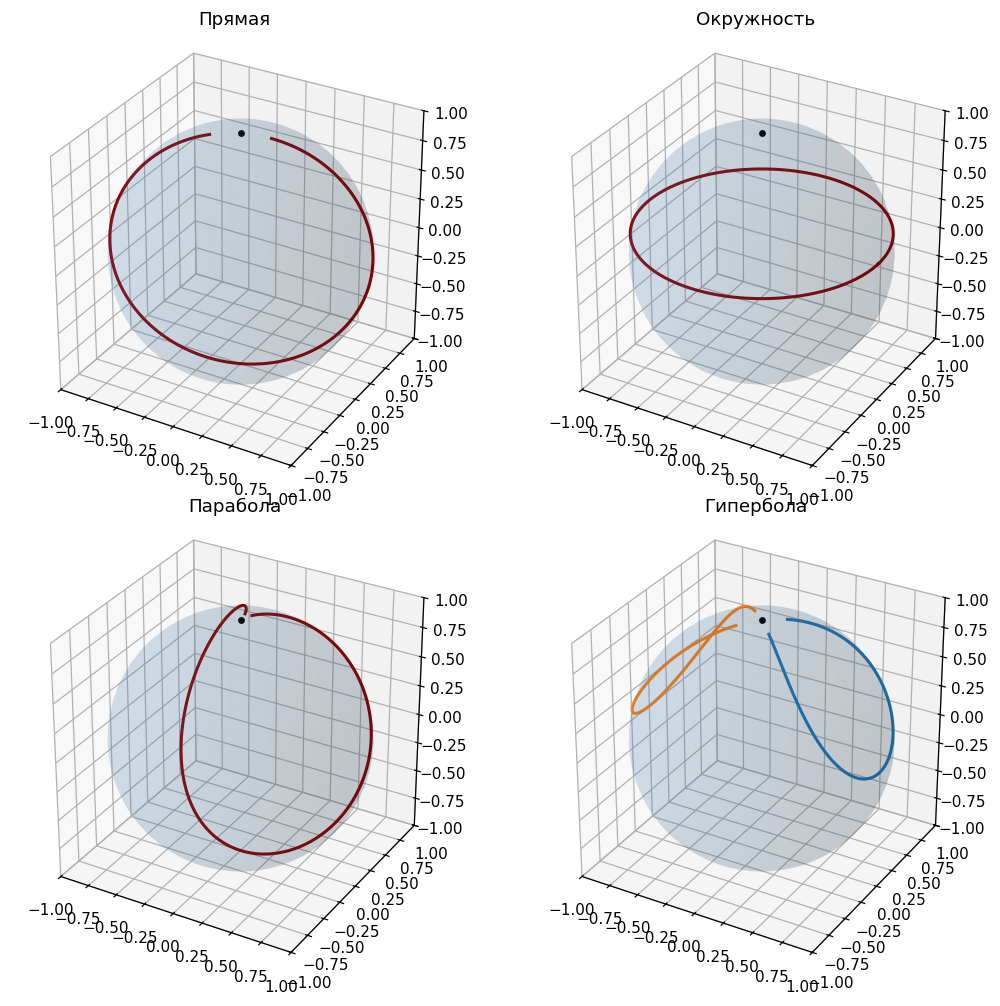

In [11]:
def sphere(z):
    x=np.real(z); y=np.imag(z); den=1+x*x+y*y
    return 2*x/den,2*y/den,(x*x+y*y-1)/den
tt=np.linspace(-8,8,900)
curves=[('Прямая',tt+.4j*tt),('Окружность',1.2*np.exp(1j*np.linspace(0,2*np.pi,900))),
        ('Парабола',tt/2+1j*(tt/2)**2),('Гипербола',np.cosh(tt/3)+1j*np.sinh(tt/3))]
u=np.linspace(0,2*np.pi,70);v=np.linspace(0,np.pi,35)
SX=np.outer(np.cos(u),np.sin(v)); SY=np.outer(np.sin(u),np.sin(v)); SZ=np.outer(np.ones_like(u),np.cos(v))
fig=plt.figure(figsize=(10,9))
for k,(title,zcurve) in enumerate(curves,1):
    ax=fig.add_subplot(2,2,k,projection='3d')
    ax.plot_surface(SX,SY,SZ,alpha=.12,color='steelblue',linewidth=0)
    if title=='Гипербола':
        for zz in (zcurve,-np.cosh(tt/3)+1j*np.sinh(tt/3)):
            ax.plot(*sphere(zz),lw=2)
    else: ax.plot(*sphere(zcurve),lw=2,color='darkred')
    ax.scatter([0],[0],[1],color='black',s=12)
    ax.set(title=title,xlim=(-1,1),ylim=(-1,1),zlim=(-1,1));ax.set_box_aspect((1,1,1))
plt.tight_layout();plt.show()

## 2.10 (второе). Логарифмическая спираль на сфере Римана

Параметризация $r=ae^{b\varphi}$ даёт $z(\varphi)=ae^{b\varphi}e^{i\varphi}$. Поскольку числа $a,b$ в условии не заданы, для рисунка выбраны **примерные** $a=0.1$, $b=0.18$. Код позволяет их поменять. При $\varphi\to+\infty$ спираль идёт к бесконечности комплексной плоскости, то есть к северному полюсу; при $\varphi\to-\infty$ — к началу координат, то есть к южному полюсу.

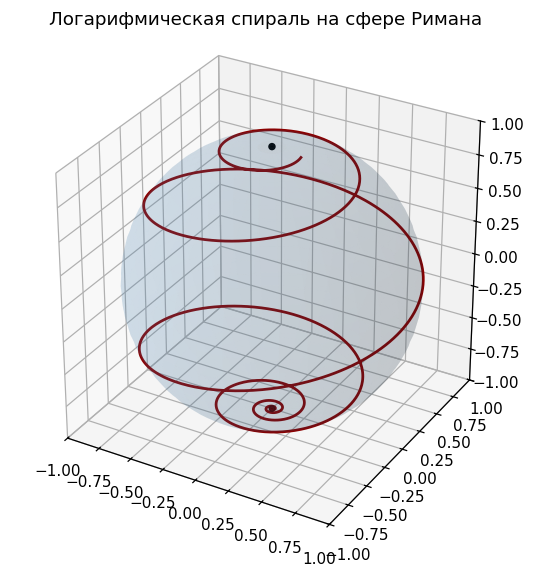

In [12]:
a210,b210=.1,.18
phi=np.linspace(-8*np.pi,8*np.pi,2500)
spiral=a210*np.exp(b210*phi+1j*phi)
fig=plt.figure(figsize=(7,6)); ax=fig.add_subplot(111,projection='3d')
ax.plot_surface(SX,SY,SZ,alpha=.12,color='steelblue',linewidth=0)
ax.plot(*sphere(spiral),color='darkred',lw=1.8)
ax.scatter([0,0],[0,0],[-1,1],color='black',s=15)
ax.set(title='Логарифмическая спираль на сфере Римана',xlim=(-1,1),ylim=(-1,1),zlim=(-1,1));ax.set_box_aspect((1,1,1))
plt.show()

## Сводка

Решены пункты 2.1–2.9 и оба пункта 2.10. Для 2.4(e) буквальный ответ — пустое множество. В задачах с численными корнями и изображениями указаны приближения; точные формулы приведены там, где они практичны.